# 🧬 10 · 宏基因组功能注释与物种组成

> 知道了群落"有谁"（物种组成），还要知道"在干什么"（功能）：
> 基因功能注释 → 通路富集 → 相对丰度可视化。
> 本节：物种分类级联、KEGG/GO/COG 功能注释概念、
> 相对丰度计算与堆叠图。

## 📋 本节要解决的问题

- 物种分类学层级怎么记？（界门纲目科属种）
- KEGG / GO / COG / eggNOG 都是什么？
- 功能注释是怎么做的？（序列比对到数据库 + 统计）
- 相对丰度堆叠图怎么读？

## 1️⃣ 物种分类级联（Taxonomy）

宏基因组常用的 16S/宏基因组分类：
`域 → 门 (Phylum) → 纲 → 目 → 科 → 属 → 种`

> 常见门：拟杆菌门（Bacteroidetes）、厚壁菌门（Firmicutes）、变形菌门（Proteobacteria）。
> 肠道菌群的"F/B 比值"常被拿来讨论代谢健康（争议较大，谨慎解读）。

In [1]:
# 简化分类注释：一条序列 -> 各层级名称
def classify_lineage(seq):
    "极简演示：按序列开头猜一个分类（示意）"
    if seq.startswith('AC'):
        return ['Bacteria', 'Bacteroidetes', 'Bacteroidia', 'Bacteroidales',
                'Bacteroidaceae', 'Bacteroides', 'Bacteroides_fragilis']
    if seq.startswith('GG'):
        return ['Bacteria', 'Firmicutes', 'Clostridia', 'Clostridiales',
                'Ruminococcaceae', 'Faecalibacterium', 'Faecalibacterium_prausnitzii']
    return ['Bacteria', 'Proteobacteria', 'Gammaproteobacteria', 'Enterobacterales',
            'Enterobacteriaceae', 'Escherichia', 'Escherichia_coli']

for seq in ['ACGTACGT', 'GGTTAACC', 'TTCCGAAT']:
    lin = classify_lineage(seq)
    print('%-8s → %s' % (seq, '; '.join(lin[:4]) + ';...'))
print('✅ 分类级联演示完成（七级：域门纲目科属种）')

ACGTACGT → Bacteria; Bacteroidetes; Bacteroidia; Bacteroidales;...
GGTTAACC → Bacteria; Firmicutes; Clostridia; Clostridiales;...
TTCCGAAT → Bacteria; Proteobacteria; Gammaproteobacteria; Enterobacterales;...
✅ 分类级联演示完成（七级：域门纲目科属种）


## 2️⃣ 功能注释数据库

| 数据库 | 类型 | 用途 |
|---|---|---|
| KEGG | 代谢通路 | 通路富集（如糖酵解、脂肪酸合成） |
| GO | 本体论 | 分子功能/生物过程/细胞组分三级 |
| COG | 直系同源簇 | 原核功能分类（信息/代谢/细胞过程） |
| eggNOG | 综合直系同源 | 跨物种功能注释 + 通路映射 |
| CAZy | 碳水化合物活性酶 | 肠道菌群解糖酶注释（GH/GT 家族） |

> **宏基因组功能注释流程**：组装（metagenome assembly）→ 基因预测 →
> 与参考蛋白库比对（DIAMOND/BLAST）→ 丰度统计 → 差异/富集。

In [2]:
print('宏基因组功能注释五步（记忆大纲）：')
for i, step in enumerate([
    '1. 质控：去接头、去低质量、去宿主（人类）序列',
    '2. 组装：MEGAHIT / metaSPAdes → contigs',
    '3. 基因预测：Prodigal / metaProdigal → ORF/蛋白序列',
    '4. 功能注释：DIAMOND 比到 KEGG/eggNOG/CAZy → COG/通路',
    '5. 丰度定量：read 映射回基因 → TPM/相对丰度 → 差异与富集',
], 1):
    print(step)
print()
print('→ 与 16S 扩增子（只需要看物种）不同，宏基因组 WGS 能直接关联"功能"')
print('✅ 功能注释流程大纲完成')

宏基因组功能注释五步（记忆大纲）：
1. 质控：去接头、去低质量、去宿主（人类）序列
2. 组装：MEGAHIT / metaSPAdes → contigs
3. 基因预测：Prodigal / metaProdigal → ORF/蛋白序列
4. 功能注释：DIAMOND 比到 KEGG/eggNOG/CAZy → COG/通路
5. 丰度定量：read 映射回基因 → TPM/相对丰度 → 差异与富集

→ 与 16S 扩增子（只需要看物种）不同，宏基因组 WGS 能直接关联"功能"
✅ 功能注释流程大纲完成


## 3️⃣ 手算示例：KEGG 通路富集（超几何思想）

> 背景 1000 个基因，其中注释到"糖酵解"通路的有 50 个；
> 实验组显著上调的基因 100 个，其中 20 个属于糖酵解。

**富集倍数（Fold enrichment）**：
$$\frac{20/100}{50/1000} = \frac{0.2}{0.05} = 4 \text{ 倍}$$

> 显著性与否要用超几何检验（类似"从 1000 个球中摸 100 个，
> 摸到该通路 50 个球中 ≥20 个"的概率）；p<0.05 且 FDR 校正后仍显著
> → 该通路在与功能相关的组分中**富集**。

In [3]:
from scipy import stats as st
# 超几何检验: 背景1000, 通路50; 取100个, 通路命中>=20
p_hyper = 1 - st.hypergeom.cdf(19, 1000, 50, 100)
print('超几何 p(≥20 命中) =', round(p_hyper, 4))
fe = (20/100) / (50/1000)
print('富集倍数(手算 4) =', fe)
assert fe == 4 and p_hyper < 0.05
print('✅ 通路富集手算验证通过（4 倍富集，显著）')

超几何 p(≥20 命中) = 0.0
富集倍数(手算 4) = 4.0
✅ 通路富集手算验证通过（4 倍富集，显著）


## 4️⃣ 相对丰度与堆叠图

**相对丰度** = 该物种/功能 reads ÷ 总 reads（×100%）。
> 用相对丰度做堆叠图可直观比较样本间组成；注意：**相对**丰度是组成型数据，
> 一个组分上升必然伴随其他组分下降（不去"绝对定量"时解读要小心）。

In [4]:
import numpy as np
# 两个样本的属级相对丰度
taxa = ['Bacteroides', 'Faecalibacterium', 'Prevotella', '其他']
s1 = np.array([40., 25, 15, 20]); s2 = np.array([10., 55, 5, 30])
s1 = s1 / s1.sum() * 100; s2 = s2 / s2.sum() * 100
print('样本1 相对丰度(%):', s1.round(1))
print('样本2 相对丰度(%):', s2.round(1))
print('样本1 和 =', round(s1.sum(), 2), ' 样本2 和 =', round(s2.sum(), 2), '（各 100%）')
assert abs(s1.sum() - 100) < 1e-9 and abs(s2.sum() - 100) < 1e-9
print('✅ 相对丰度归一化完成')

样本1 相对丰度(%): [40. 25. 15. 20.]
样本2 相对丰度(%): [10. 55.  5. 30.]
样本1 和 = 100.0  样本2 和 = 100.0 （各 100%）
✅ 相对丰度归一化完成


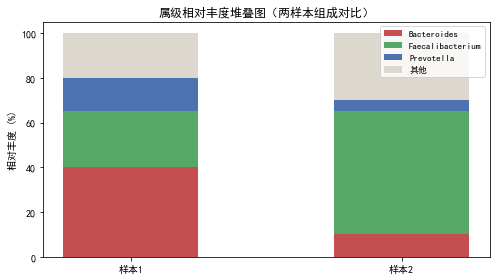

→ 样本1 以 Bacteroides 为主，样本2 以 Faecalibacterium 为主 → 组成差异明显


In [5]:
# 堆叠图可视化
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

fig, ax = plt.subplots(figsize=(7, 4))
X = np.vstack([s1, s2])
bottom = np.zeros(2)
colors = ['#C44E52', '#55A868', '#4C72B0', '#DDD8CE']
for i, (t, c) in enumerate(zip(taxa, colors)):
    ax.bar(['样本1', '样本2'], X[:, i], bottom=bottom, label=t, color=c, width=.5)
    bottom += X[:, i]
ax.set_ylabel('相对丰度 (%)')
ax.set_title('属级相对丰度堆叠图（两样本组成对比）')
ax.legend(loc='upper right', fontsize=9)
plt.tight_layout()
plt.show()
print('→ 样本1 以 Bacteroides 为主，样本2 以 Faecalibacterium 为主 → 组成差异明显')

## ✅ 自测清单

- [ ] 能背出七级分类层级与常见门
- [ ] 能说出 KEGG/GO/COG 的用途区别
- [ ] 能手算富集倍数并理解超几何检验
- [ ] 能解释相对丰度的"组成型"陷阱